<a href="https://colab.research.google.com/github/Adhityayusuf/mesin-learning/blob/main/JS05/JS05_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 - Upload dan Load Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Upload file spam.csv (khusus Google Colab). Dilewati jika file sudah ada.
if not os.path.exists('spam.csv'):
    from google.colab import files
    files.upload()  # pilih spam.csv

df = pd.read_csv('spam.csv', encoding='latin-1')  # encoding latin-1 karena data bukan UTF-8
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## Langkah 2 - Preprocessing

In [2]:
# 2a. Drop 3 kolom kosong dan ubah nama kolom
df = df.drop(df.iloc[:, 2:], axis=1)
df.columns = ['Labels', 'SMS']
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# 2b. Inspeksi data
print(df['Labels'].value_counts())
print('\n')
print(df.info())
print('\n')
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


In [4]:
# 2c. Encode label (spam = 1, ham = 0)
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

# 2d. Pisahkan fitur dan label
X = df['SMS'].values
y = df['Labels'].values

df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## Langkah 3 - Split Data
Split dilakukan **sekali** dan dipakai oleh kedua model, sehingga perbandingan CountVectorizer vs TF-IDF adil (data train dan test sama persis). Split dilakukan sebelum ekstraksi fitur untuk mencegah *information leakage*.

In [5]:
from sklearn.model_selection import train_test_split

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50
)

print('Data train:', len(X_train_text))
print('Data test :', len(X_test_text))

Data train: 4457
Data test : 1115


## Langkah 4 - Model 1: Multinomial NB + CountVectorizer (stop_words aktif)

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Ekstraksi fitur (fit hanya pada data train)
bow = CountVectorizer(stop_words='english')
X_train_bow = bow.fit_transform(X_train_text)
X_test_bow = bow.transform(X_test_text)

print(f'Jumlah fitur (kata): {len(bow.get_feature_names_out())}')
print(f'Dimensi data train : {X_train_bow.shape}')

# Training
mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train)

# Prediksi
y_pred_train_bow = mnb_bow.predict(X_train_bow)
y_pred_test_bow = mnb_bow.predict(X_test_bow)

print(f'\nAkurasi data train: {accuracy_score(y_train, y_pred_train_bow):.4f}')
print(f'Akurasi data test : {accuracy_score(y_test, y_pred_test_bow):.4f}')

Jumlah fitur (kata): 7466
Dimensi data train : (4457, 7466)

Akurasi data train: 0.9946
Akurasi data test : 0.9830


In [7]:
# Evaluasi lengkap Model 1
print('=== CountVectorizer (stop_words) ===')
print(classification_report(y_test, y_pred_test_bow, target_names=['ham', 'spam']))

cm_bow = confusion_matrix(y_test, y_pred_test_bow)
print('Confusion matrix:')
print(cm_bow)

=== CountVectorizer (stop_words) ===
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115

Confusion matrix:
[[951   3]
 [ 16 145]]


## Langkah 5 - Model 2: Multinomial NB + TF-IDF (stop_words aktif)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Ekstraksi fitur TF-IDF (fit hanya pada data train)
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print(f'Jumlah fitur (kata): {len(tfidf.get_feature_names_out())}')
print(f'Dimensi data train : {X_train_tfidf.shape}')

# Training
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

# Prediksi
y_pred_train_tfidf = mnb_tfidf.predict(X_train_tfidf)
y_pred_test_tfidf = mnb_tfidf.predict(X_test_tfidf)

print(f'\nAkurasi data train: {accuracy_score(y_train, y_pred_train_tfidf):.4f}')
print(f'Akurasi data test : {accuracy_score(y_test, y_pred_test_tfidf):.4f}')

Jumlah fitur (kata): 7466
Dimensi data train : (4457, 7466)

Akurasi data train: 0.9843
Akurasi data test : 0.9605


In [9]:
# Evaluasi lengkap Model 2
print('=== TF-IDF (stop_words) ===')
print(classification_report(y_test, y_pred_test_tfidf, target_names=['ham', 'spam']))

cm_tfidf = confusion_matrix(y_test, y_pred_test_tfidf)
print('Confusion matrix:')
print(cm_tfidf)

=== TF-IDF (stop_words) ===
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115

Confusion matrix:
[[954   0]
 [ 44 117]]


## Langkah 6 - Perbandingan Kedua Model

In [10]:
# Tabel perbandingan (precision, recall, F1 dihitung untuk kelas spam)
def ringkas(nama, y_pred_train, y_pred_test):
    return {
        'Model': nama,
        'Akurasi Train': accuracy_score(y_train, y_pred_train),
        'Akurasi Test': accuracy_score(y_test, y_pred_test),
        'Precision (spam)': precision_score(y_test, y_pred_test),
        'Recall (spam)': recall_score(y_test, y_pred_test),
        'F1 (spam)': f1_score(y_test, y_pred_test),
    }

hasil = pd.DataFrame([
    ringkas('CountVectorizer + stop_words', y_pred_train_bow, y_pred_test_bow),
    ringkas('TF-IDF + stop_words', y_pred_train_tfidf, y_pred_test_tfidf),
]).set_index('Model')

hasil.round(4)

,Akurasi Train,Akurasi Test,Precision (spam),Recall (spam),F1 (spam)
Model,,,,,
CountVectorizer + stop_words,0.9946,0.9830,0.9797,0.9006,0.9385
TF-IDF + stop_words,0.9843,0.9605,1.0000,0.7267,0.8417


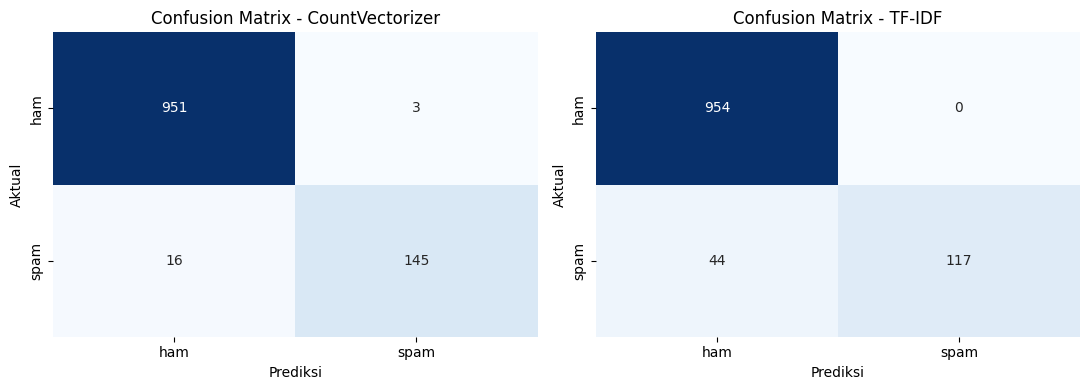

In [11]:
# Visualisasi: confusion matrix kedua model
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cm, judul in zip(axes, [cm_bow, cm_tfidf], ['CountVectorizer', 'TF-IDF']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    ax.set_title(f'Confusion Matrix - {judul}')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

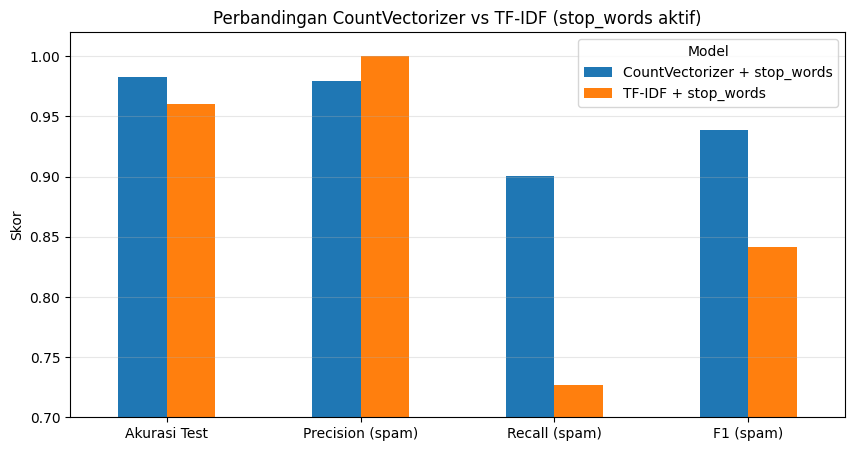

In [12]:
# Visualisasi: perbandingan metrik
metrik = ['Akurasi Test', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']
hasil[metrik].T.plot(kind='bar', figsize=(10, 5))
plt.title('Perbandingan CountVectorizer vs TF-IDF (stop_words aktif)')
plt.ylabel('Skor')
plt.ylim(0.7, 1.02)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Model')
plt.show()

## Langkah 7 - Kesimpulan

In [13]:
# Kesimpulan otomatis berdasarkan hasil di atas
a = hasil.loc['CountVectorizer + stop_words']
b = hasil.loc['TF-IDF + stop_words']

print('Akurasi Test  -> CountVectorizer: %.4f | TF-IDF: %.4f' % (a['Akurasi Test'], b['Akurasi Test']))
print('Precision spam-> CountVectorizer: %.4f | TF-IDF: %.4f' % (a['Precision (spam)'], b['Precision (spam)']))
print('Recall spam   -> CountVectorizer: %.4f | TF-IDF: %.4f' % (a['Recall (spam)'], b['Recall (spam)']))
print('F1 spam       -> CountVectorizer: %.4f | TF-IDF: %.4f' % (a['F1 (spam)'], b['F1 (spam)']))

# Pemenang ditentukan dari F1 kelas spam (data tidak seimbang), lalu akurasi sebagai pembanding
if abs(a['F1 (spam)'] - b['F1 (spam)']) < 1e-9:
    terbaik = 'CountVectorizer' if a['Akurasi Test'] >= b['Akurasi Test'] else 'TF-IDF'
else:
    terbaik = 'CountVectorizer' if a['F1 (spam)'] > b['F1 (spam)'] else 'TF-IDF'

print(f'\n>>> Fitur terbaik pada data spam.csv: {terbaik}')

Akurasi Test  -> CountVectorizer: 0.9830 | TF-IDF: 0.9605
Precision spam-> CountVectorizer: 0.9797 | TF-IDF: 1.0000
Recall spam   -> CountVectorizer: 0.9006 | TF-IDF: 0.7267
F1 spam       -> CountVectorizer: 0.9385 | TF-IDF: 0.8417

>>> Fitur terbaik pada data spam.csv: CountVectorizer
